# 02 · Exploratory data analysis

Univariate, bivariate and multivariate views of the workforce and of attrition. Every rate is reported with its
group size and a 95% Wilson interval, and every test result with a Benjamini-Hochberg adjusted p-value. The functions
are those behind the dashboard's *Workforce* and *Attrition* pages (`talentscope.analytics`).

> These are **associations in synthetic data**. None of them shows that changing an attribute would change whether
> someone leaves.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from talentscope import config
from talentscope.reporting import figures as F
F.setup()
print("TalentScope root:", ROOT.name, "| seed", config.RANDOM_SEED)

TalentScope root: TalentScope | seed 42


In [2]:
from talentscope.data import load_dataset, schema
from talentscope.analytics import (workforce_kpis, rate_by, association_ranking, numeric_comparison,
                                   headline_findings, correlation_matrix, cramers_v_matrix, crosstab_rates, DIMENSIONS)
df = load_dataset()
k = workforce_kpis(df)
pd.Series({key: v for key, v in k.items() if key != "rate_ci"}).to_frame("value")

,value
headcount,1470.000
left,237.000
stayed,1233.000
attrition_rate,0.161
avg_tenure,7.008
median_tenure,5.000
avg_income,6502.931
median_income,4919.000
avg_age,36.924
overtime_share,0.283


## 1. Univariate: the workforce

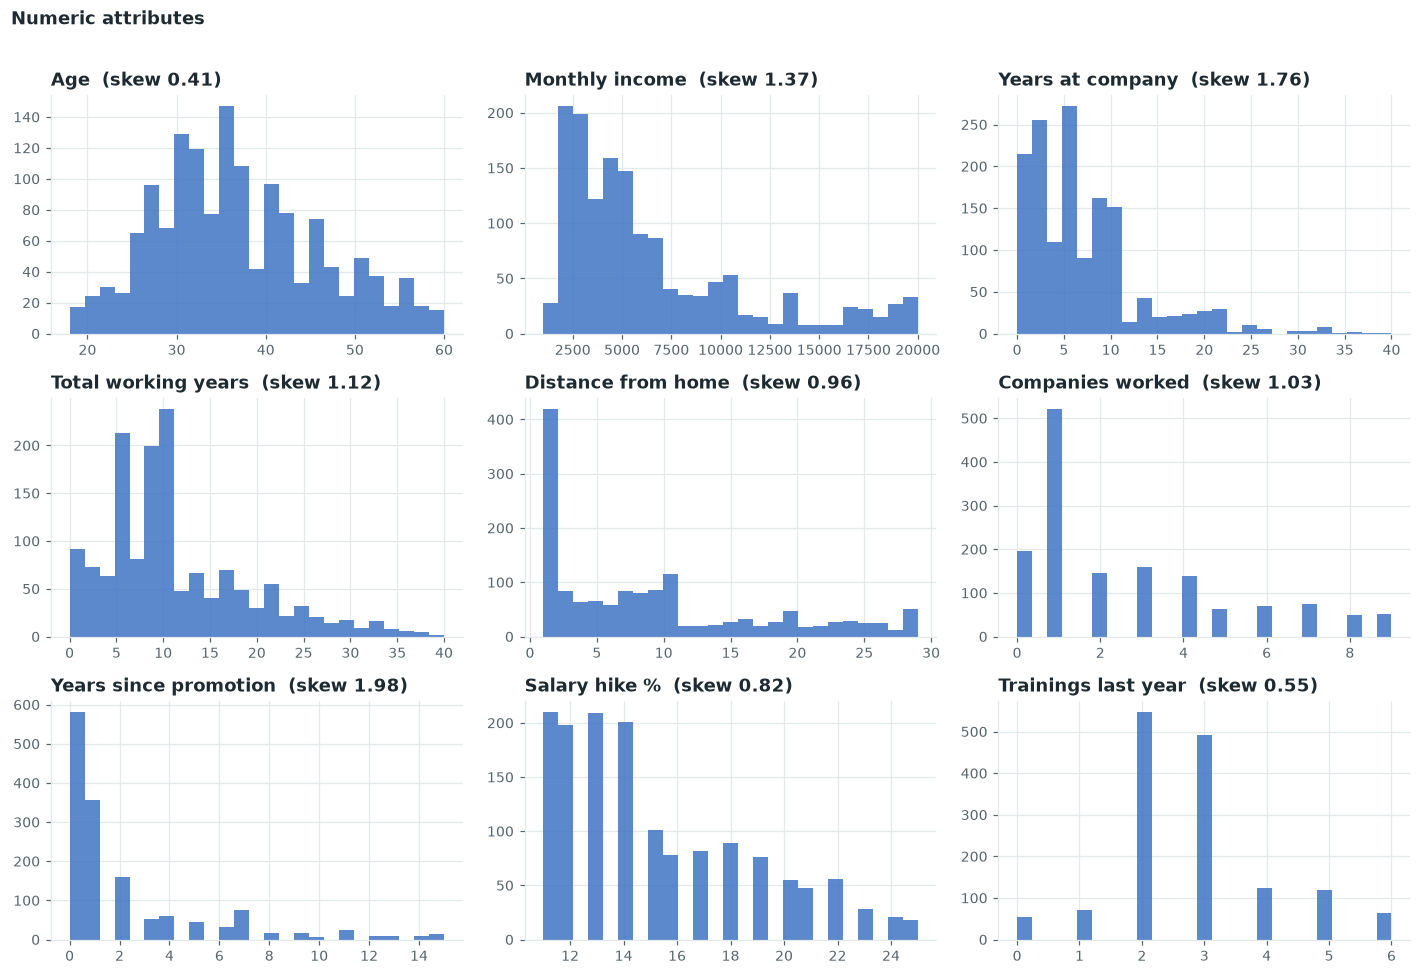

In [3]:
num = ["Age", "MonthlyIncome", "YearsAtCompany", "TotalWorkingYears", "DistanceFromHome", "NumCompaniesWorked",
       "YearsSinceLastPromotion", "PercentSalaryHike", "TrainingTimesLastYear"]
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, c in zip(axes.flat, num):
    ax.hist(df[c], bins=25, color=F.BLUE, alpha=0.85)
    ax.set_title(f"{schema.PRETTY_NAMES[c]}  (skew {df[c].skew():.2f})")
fig.suptitle("Numeric attributes", x=0.01, ha="left", fontweight="bold"); fig.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

Income, tenure, total experience and years since promotion are right-skewed: most employees are early in their
careers, with a long tail of senior, long-serving staff. Age is roughly symmetric around 37.

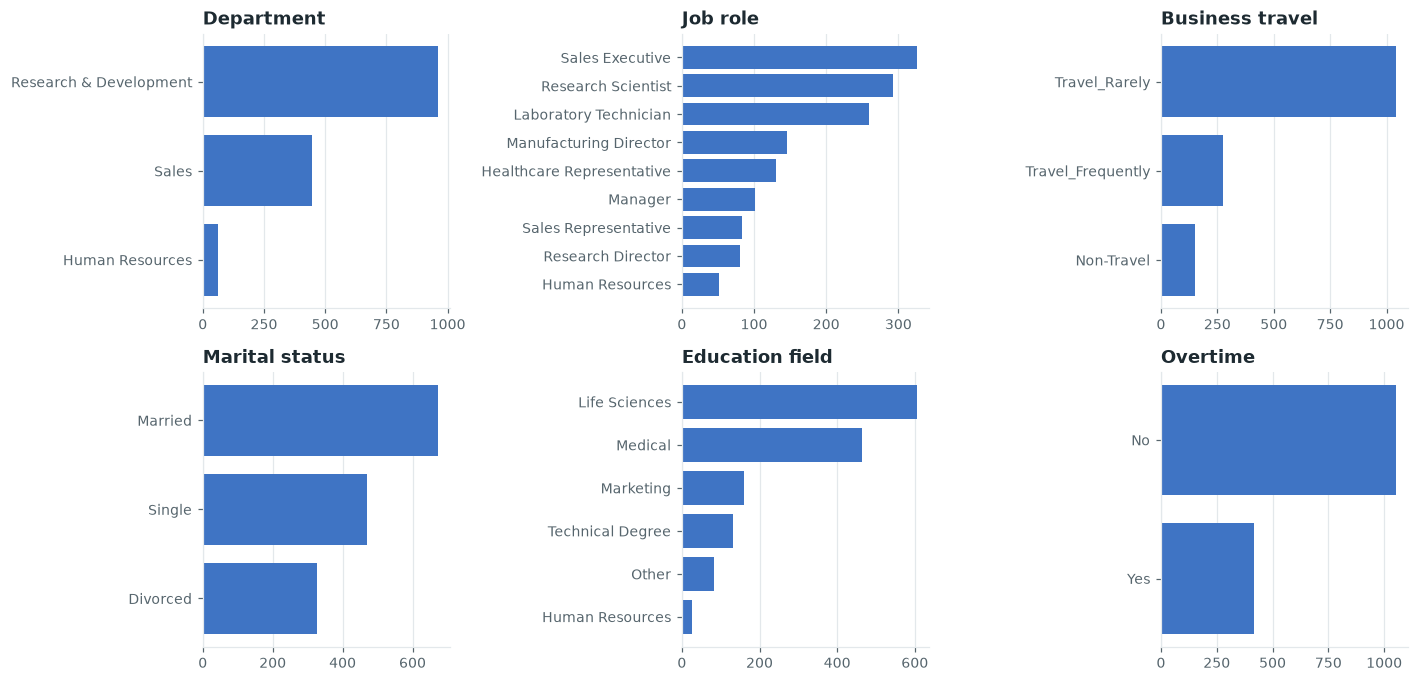

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, c in zip(axes.flat, ["Department", "JobRole", "BusinessTravel", "MaritalStatus", "EducationField", "OverTime"]):
    vc = df[c].value_counts()
    ax.barh(vc.index[::-1], vc.values[::-1], color=F.BLUE); ax.set_title(schema.PRETTY_NAMES[c])
    ax.grid(axis="y", visible=False)
fig.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

## 2. Bivariate: attrition rate by group

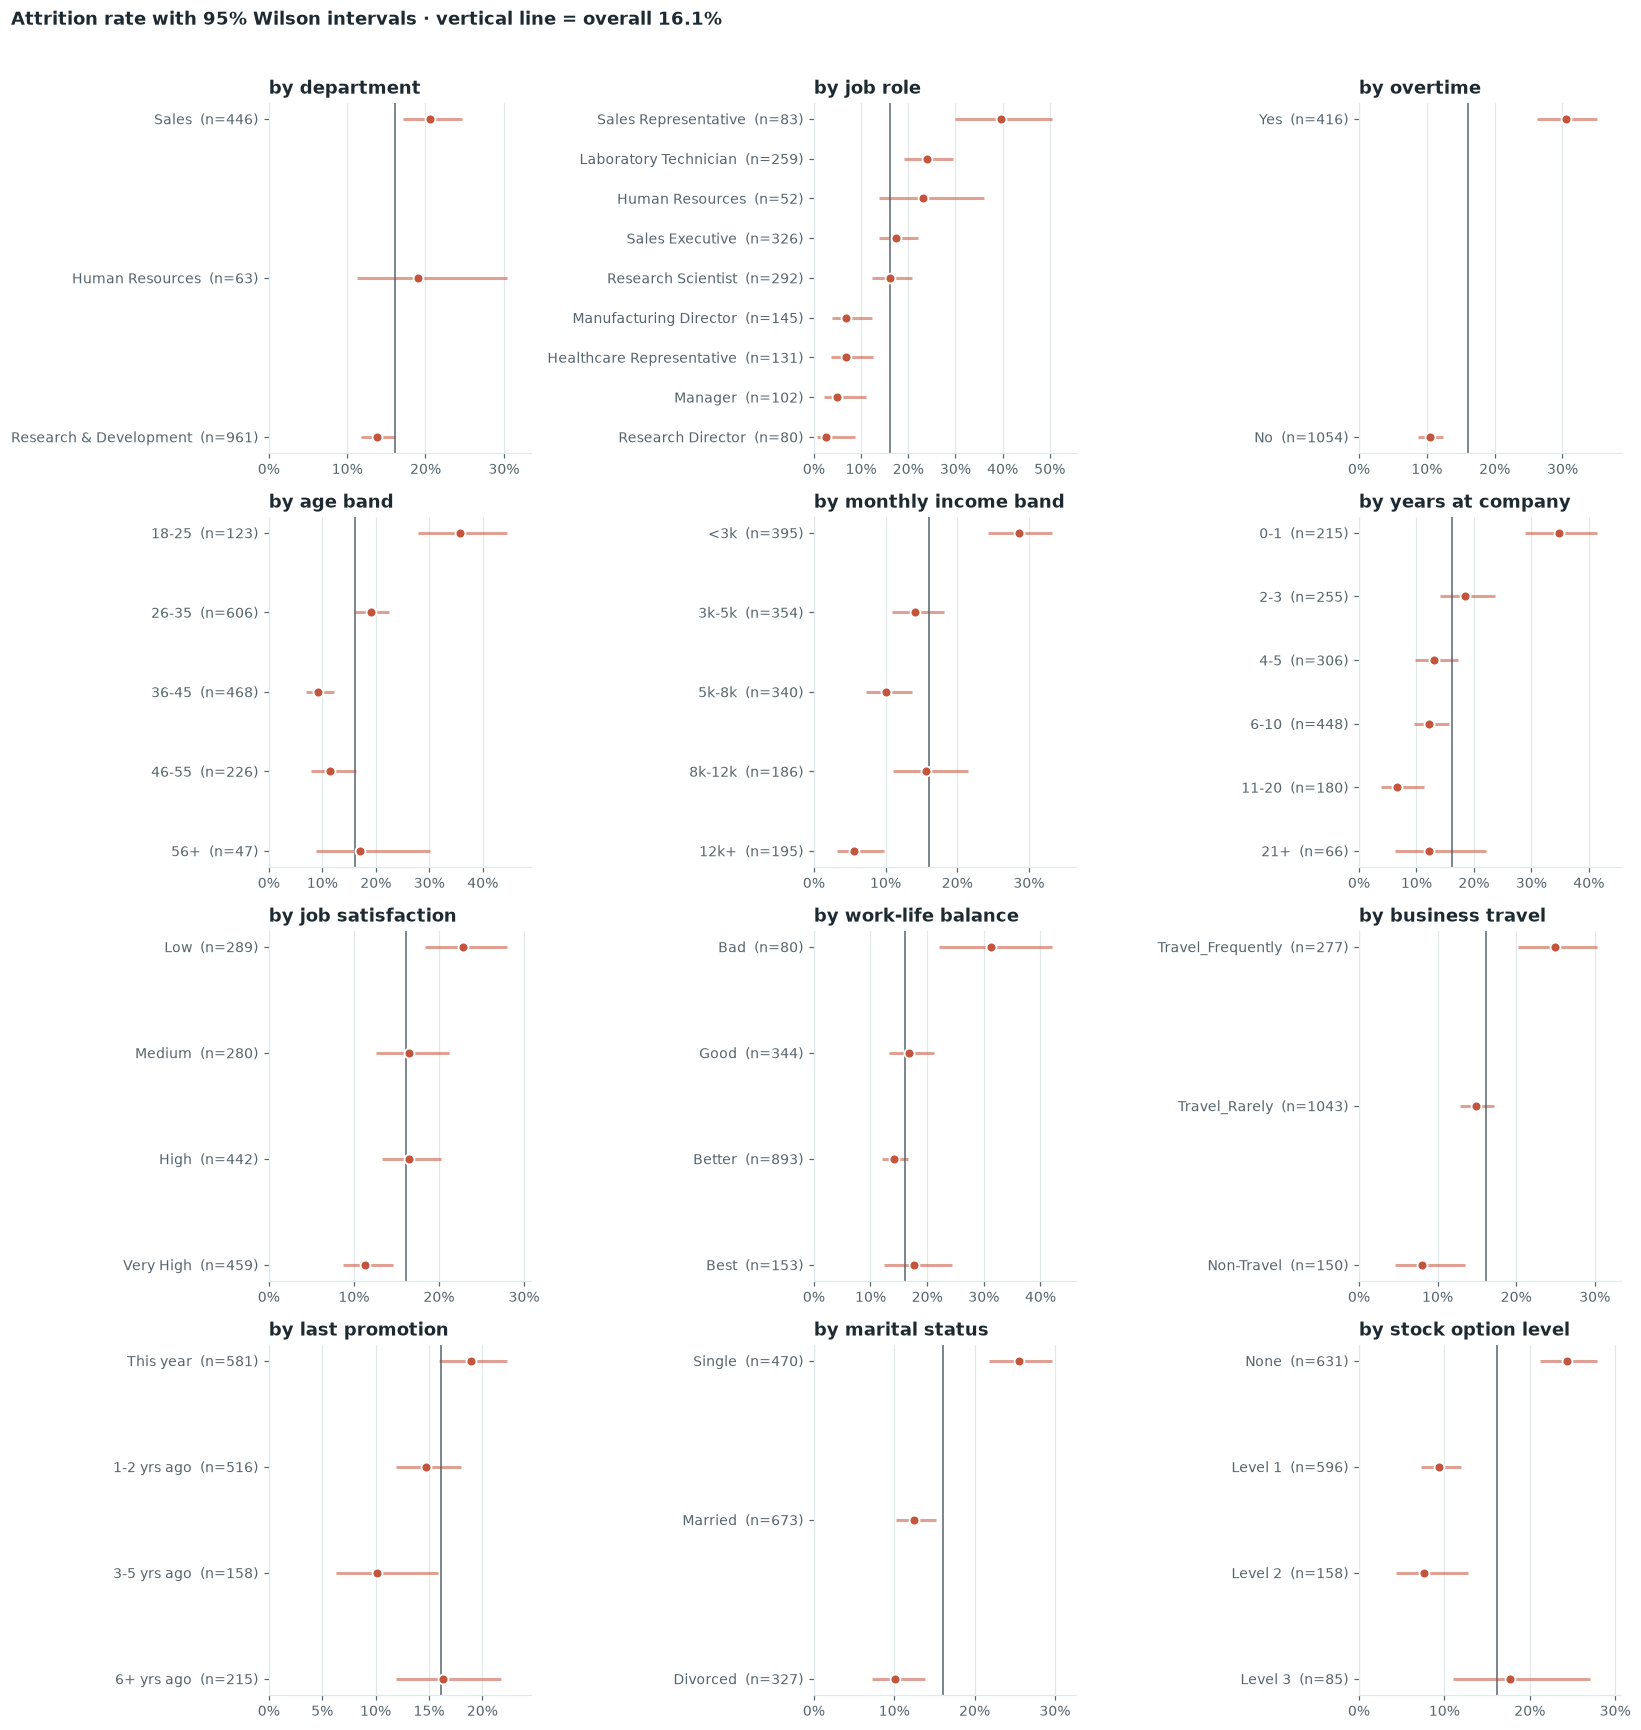

In [5]:
overall = df["AttritionFlag"].mean()
dims = ["department", "job_role", "overtime", "age", "income", "tenure", "job_satisfaction", "work_life", "travel",
        "promotion", "marital", "stock"]
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
for ax, key in zip(axes.flat, dims):
    col, label, ordered = DIMENSIONS[key]
    F.rate_dots(ax, rate_by(df, col), overall, f"by {label.lower()}", ordered=ordered)
fig.suptitle(f"Attrition rate with 95% Wilson intervals · vertical line = overall {overall:.1%}", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

In [6]:
for f in headline_findings(df, k=6):
    print("•", f["text"], f"({f['ratio']:.1f}x)")

• Overtime = Yes: 31% attrition (95% CI 26%-35%, n = 416) against 10% for everyone else. (2.9x)
• Job role = Sales Representative: 40% attrition (95% CI 30%-51%, n = 83) against 15% for everyone else. (2.7x)
• Years at company = 0-1: 35% attrition (95% CI 29%-41%, n = 215) against 13% for everyone else. (2.7x)
• Job level = Level 1: 26% attrition (95% CI 23%-30%, n = 543) against 10% for everyone else. (2.6x)
• Age band = 18-25: 36% attrition (95% CI 28%-45%, n = 123) against 14% for everyone else. (2.5x)
• Monthly income band = <3k: 29% attrition (95% CI 24%-33%, n = 395) against 12% for everyone else. (2.5x)


**Observations**

* **Overtime** is the clearest single gap: about 31% of overtime workers left against 10% of everyone else.
* **Career stage** dominates the rest. Attrition is highest under 26, in the first year or two at the company, at job
  level 1, in the lowest income band and among employees with no stock options. These attributes describe overlapping
  groups of junior staff, so they are not independent findings.
* **Sales Representatives** (40%) and **Laboratory Technicians** (24%) have the highest role rates. Directors and
  managers have the lowest, at around 3% to 7%.
* **Single** employees and **frequent travellers** leave more often.
* **Null or weak results:** promotion recency shows no consistent pattern, since the intervals overlap. Satisfaction
  scores matter mainly at the "Low" level, and `PerformanceRating` (two levels) shows almost no difference.

In [7]:
pd.concat({"Performance rating": rate_by(df, "PerformanceRating"), "Gender": rate_by(df, "Gender")})[
    ["group", "n", "left", "rate", "ci_low", "ci_high"]]

group     n  left   rate  ci_low  ci_high
Performance rating 0       3  1244   200  0.161   0.141    0.182
                   1       4   226    37  0.164   0.121    0.218
Gender             0  Female   588    87  0.148   0.122    0.179
                   1    Male   882   150  0.170   0.147    0.196

## 3. Statistical tests across all 30 attributes

In [8]:
assoc = association_ranking(df)
assoc[["label", "test", "effect_name", "effect", "direction", "p_value", "p_adjusted", "significant"]]

,label,test,effect_name,effect,direction,p_value,p_adjusted,significant
0,Total working years,Mann-Whitney U,|rank-biserial r|,0.312,lower among leavers,2.400e-14,1.770e-13,True
1,Monthly income,Mann-Whitney U,|rank-biserial r|,0.311,lower among leavers,2.951e-14,1.770e-13,True
2,Years at company,Mann-Whitney U,|rank-biserial r|,0.298,lower among leavers,2.916e-13,1.458e-12,True
3,Years in current role,Mann-Whitney U,|rank-biserial r|,0.280,lower among leavers,4.430e-12,1.661e-11,True
4,Years with manager,Mann-Whitney U,|rank-biserial r|,0.272,lower among leavers,1.807e-11,6.023e-11,True
5,Age,Mann-Whitney U,|rank-biserial r|,0.269,lower among leavers,5.304e-11,1.591e-10,True
6,Overtime,chi-square,Cramer's V,0.246,,3.862e-21,1.158e-19,True
7,Job role,chi-square,Cramer's V,0.242,,2.752e-15,4.129e-14,True
8,Job level,chi-square,Cramer's V,0.222,,6.635e-15,6.635e-14,True
9,Stock option level,chi-square,Cramer's V,0.203,,4.379e-13,1.877e-12,True


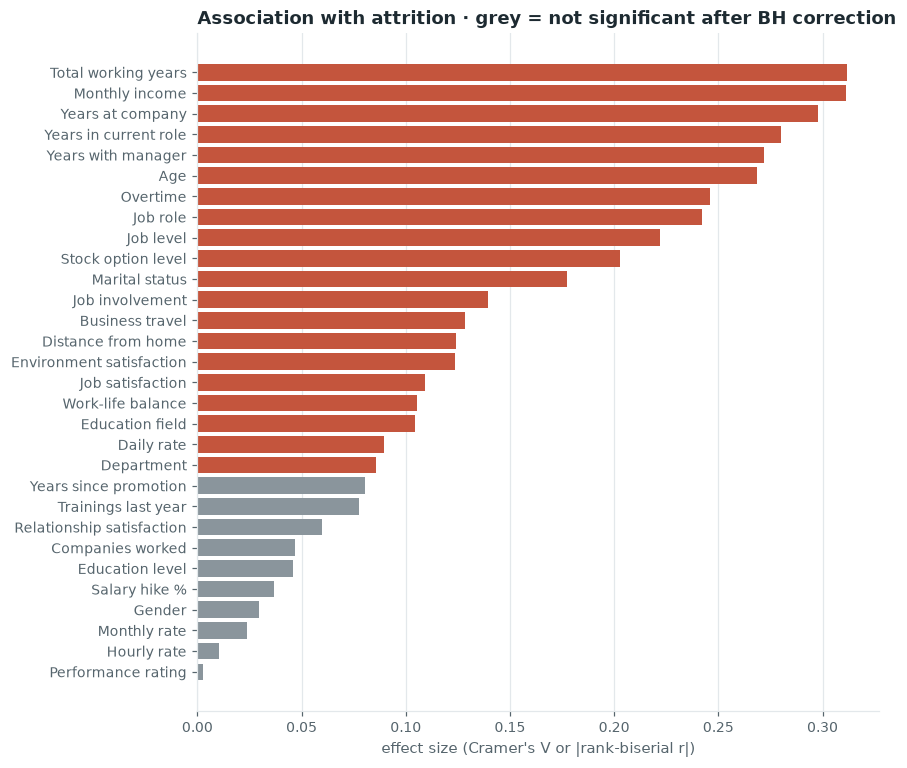

20 of 30 attributes significant at BH-adjusted p < 0.05


In [9]:
a = assoc.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(a["label"], a["effect"], color=[F.CLAY if s else F.NEUTRAL for s in a["significant"]])
ax.set_xlabel("effect size (Cramer's V or |rank-biserial r|)")
ax.set_title("Association with attrition · grey = not significant after BH correction"); ax.grid(axis="y", visible=False)
plt.show()
print(f"{assoc['significant'].sum()} of {len(assoc)} attributes significant at BH-adjusted p < 0.05")

Most attributes are significantly associated with attrition, but every effect is **small to moderate**: the largest is
around 0.3. That matches the leakage screen in notebook 01. No single attribute is decisive, so a model has to combine
them.

Ten attributes are *not* significant after correction: performance rating, hourly and monthly rate, gender, salary
hike, education, number of companies worked, relationship satisfaction, trainings last year and years since
promotion. They all stay in the model, because dropping features based on full-data tests would leak information from
the test set into feature selection.

Two of them, **years since promotion** and **companies worked**, matter a lot to the model in notebook 07 despite
weak univariate effects. Once career stage is held fixed, a long wait for promotion or frequent job changes become
informative. A univariate test cannot see that kind of conditional effect.

In [10]:
numeric_comparison(df).sort_values("rank_biserial")[["label", "median_left", "median_stayed", "rank_biserial", "p_adjusted"]]

,label,median_left,median_stayed,rank_biserial,p_adjusted
8,Total working years,7.0,10.0,-0.312,2.066e-13
4,Monthly income,3202.0,5204.0,-0.311,2.066e-13
10,Years at company,3.0,6.0,-0.298,1.361e-12
11,Years in current role,2.0,3.0,-0.280,1.550e-11
13,Years with manager,2.0,3.0,-0.272,5.059e-11
0,Age,32.0,36.0,-0.269,1.238e-10
1,Daily rate,699.0,817.0,-0.089,5.076e-02
12,Years since promotion,1.0,1.0,-0.080,6.406e-02
9,Trainings last year,2.0,3.0,-0.078,6.621e-02
7,Salary hike %,14.0,14.0,-0.037,4.264e-01


## 4. Multivariate structure

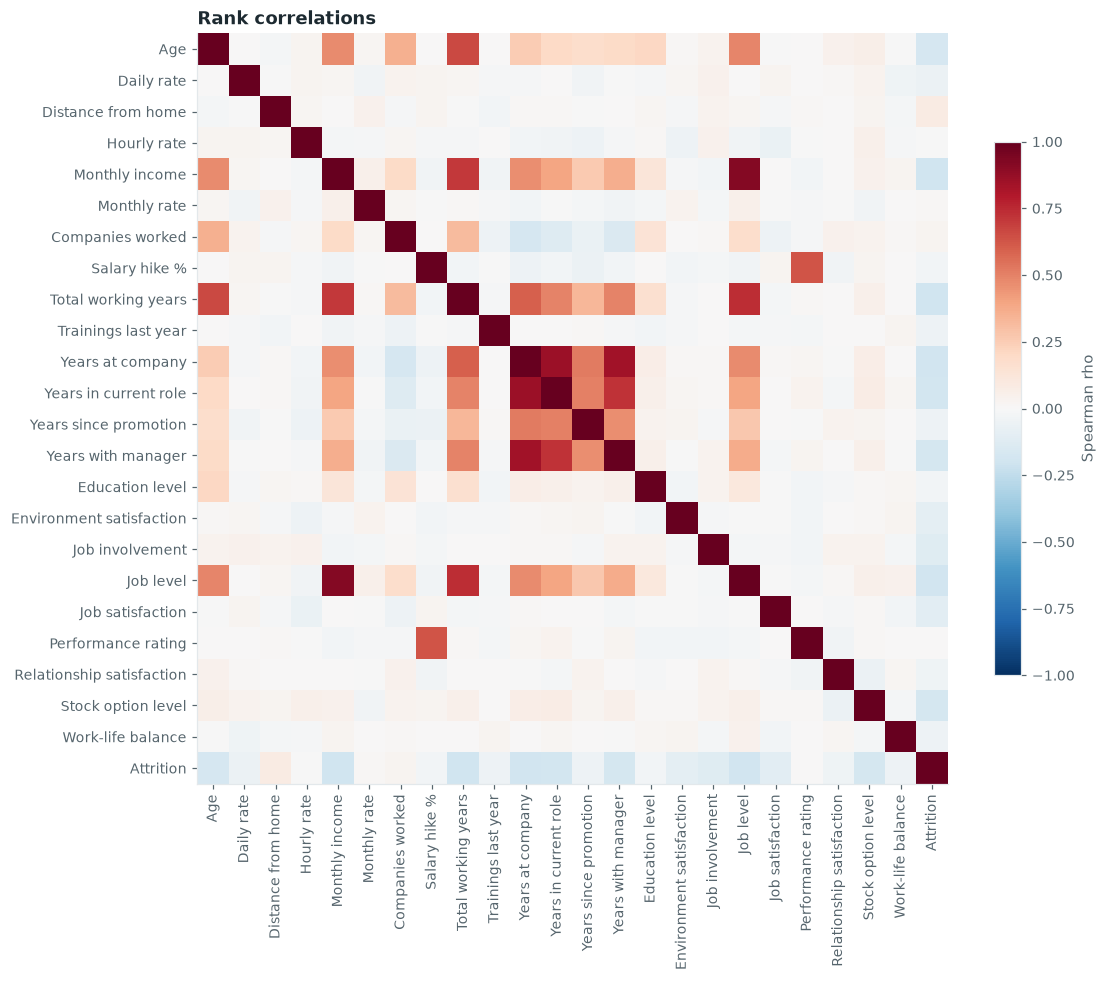

In [11]:
cm = correlation_matrix(df)
labels = [schema.PRETTY_NAMES.get(c, "Attrition") for c in cm.columns]
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(cm.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=90); ax.set_yticks(range(len(labels)), labels); ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman rho"); ax.set_title("Rank correlations"); plt.show()

A tight block links **age, total working years, job level, monthly income and the four tenure counts**. That block is
the "career stage" factor behind most of the univariate gaps above. Satisfaction surveys are nearly uncorrelated with
each other and with the career block, so they add independent information.

In [12]:
cv = cramers_v_matrix(df)
cv.index = cv.columns = [schema.PRETTY_NAMES.get(c, c) for c in cv.columns]
cv.round(2)

,Business travel,Department,Education field,Gender,Job role,Marital status,Overtime,Attrition
Business travel,1.00,0.01,0.04,0.05,0.06,0.05,0.04,0.13
Department,0.01,1.00,0.59,0.04,0.94,0.05,0.01,0.09
Education field,0.04,0.59,1.00,0.04,0.34,0.06,0.03,0.10
Gender,0.05,0.04,0.04,1.00,0.10,0.05,0.04,0.03
Job role,0.06,0.94,0.34,0.10,1.00,0.10,0.07,0.24
Marital status,0.05,0.05,0.06,0.05,0.10,1.00,0.02,0.18
Overtime,0.04,0.01,0.03,0.04,0.07,0.02,1.00,0.25
Attrition,0.13,0.09,0.10,0.03,0.24,0.18,0.25,1.00


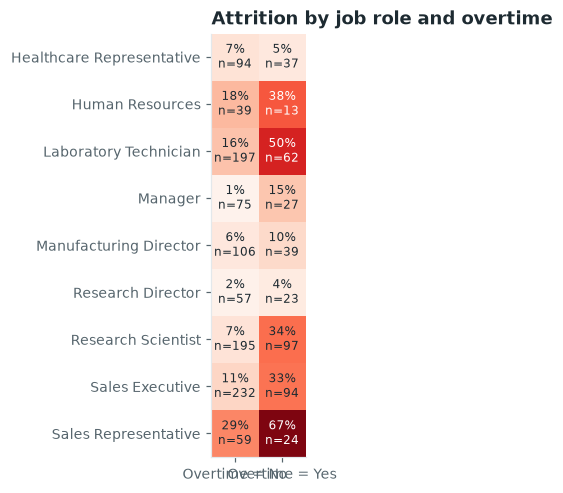

In [13]:
rates, counts = crosstab_rates(df, "JobRole", "OverTime", min_n=10)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(rates.values, cmap="Reds", vmin=0, vmax=0.7)
for i in range(rates.shape[0]):
    for j in range(rates.shape[1]):
        v = rates.values[i, j]
        ax.text(j, i, "" if np.isnan(v) else f"{v:.0%}\nn={counts.values[i, j]}", ha="center", va="center", fontsize=8,
                color="white" if v > 0.35 else F.INK)
ax.set_xticks([0, 1], [f"Overtime = {c}" for c in rates.columns]); ax.set_yticks(range(len(rates)), rates.index); ax.grid(False)
ax.set_title("Attrition by job role and overtime"); plt.show()

**Interaction.** Overtime is associated with higher attrition in *every* role, so the overtime gap is not just a role
effect. Sales Representatives who work overtime have the highest rate in the table. Their cell is small, though, so the
exact figure is uncertain.

## Summary

* Attrition concentrates among junior, early-tenure, lower-paid employees, among those working overtime, and in a few
  roles (Sales Representative, Laboratory Technician).
* All effects are moderate, and many attributes overlap, so a multivariate model is needed and should be expected to be
  imperfect.
* Weak or null attributes: promotion recency, performance rating, gender, education and the three "rate" pay fields.